# Why Python For Finance

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
import matplotlib

/Users/duanemadziva/Documents/Programming/GitHub Repositories/Python-Finance/finance_analytics/lib/python3.7/site-packages/urllib3/__init__.py:38: NotOpenSSLWarning: urllib3 v2.0 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  exceptions.NotOpenSSLWarning,


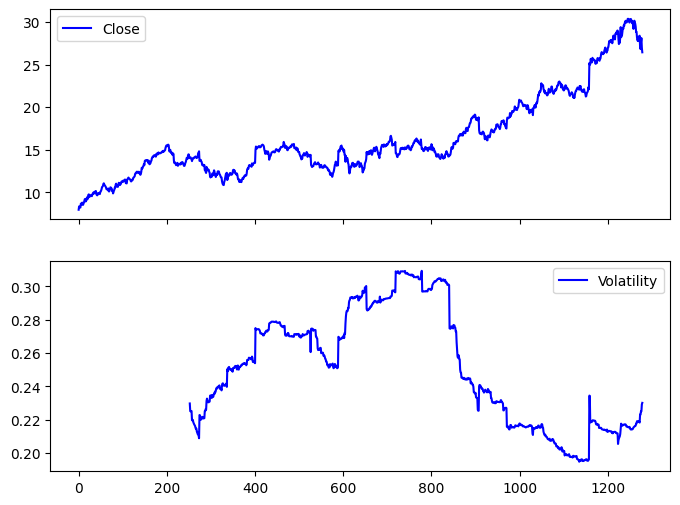

In [10]:
# google data
goog = yf.download("goog", start = "2009-03-14", end = "2014-04-14", progress = False)
goog.columns = goog.columns.get_level_values('Price') # remove multi-index

goog = (
    goog
    .reset_index()
    .assign(
        Log_Ret = lambda d: np.log(d['Close'] / d['Close'].shift(1)),
        Volatility = lambda d: d['Log_Ret'].rolling(window = 252).std() * np.sqrt(252)
    )
)


# plot volatility
%matplotlib inline
goog[['Close', 'Volatility']].plot(subplots = True, color = 'blue', figsize = (8, 6));